=== EXPERT SYSTEM ===
Student inputs: {'attendance': 40, 'marks': 45, 'assignments': 60}
Recommendation: Needs academic support
Explanation: ['Attendance below 50%', 'Marks below 50']

=== IMITATION LEARNING ===
Accuracy: 1.0

Classification report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00         5
           1       1.00      1.00      1.00         4

    accuracy                           1.00         9
   macro avg       1.00      1.00      1.00         9
weighted avg       1.00      1.00      1.00         9

New student: {'attendance': 45, 'marks': 42, 'assignments': 65}
Learned recommendation: Needs academic support

=== LEARNED MODEL RULES ===
|--- marks <= 59.00
|   |--- class: 1
|--- marks >  59.00
|   |--- class: 0


Feature importance:
attendance: 0.000
marks: 1.000
assignments: 0.000

=== GROUP FAIRNESS AUDIT ===
       actual_support_rate  predicted_support_rate  group_size
group                                     

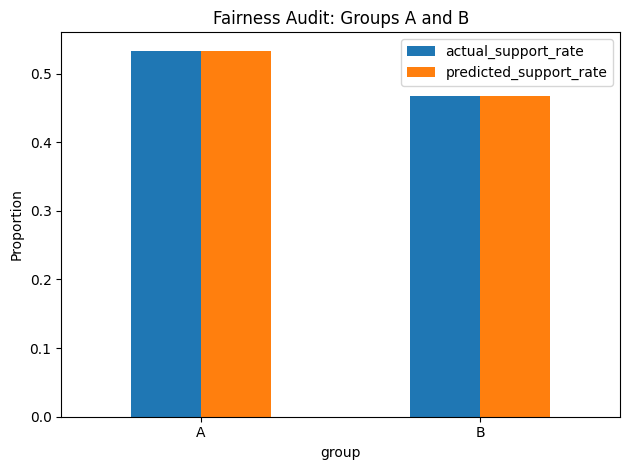


=== BEFORE AND AFTER ===
Before update: Needs support
After update: Needs support

Rule-based comparison for attendance=80, marks=45, assignments=80
Before rule change: Needs academic support ['Marks below 50']
After rule change: No additional support indicated []


In [1]:

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report

# ==========================================
# 1. KNOWLEDGE BASE: HUMAN EXPERT EXAMPLES
# ==========================================

data = pd.DataFrame({
    "attendance": [
        20, 30, 40, 45, 50, 55, 60, 65, 70, 75,
        80, 85, 90, 95, 35, 48, 58, 68, 78, 88,
        25, 42, 52, 62, 72, 82, 92, 38, 67, 77
    ],
    "marks": [
        20, 35, 40, 45, 55, 40, 60, 50, 70, 65,
        80, 75, 90, 85, 30, 48, 58, 62, 72, 88,
        25, 38, 52, 55, 68, 78, 92, 42, 60, 74
    ],
    "assignments": [
        20, 30, 50, 60, 60, 70, 80, 60, 90, 80,
        90, 85, 95, 90, 25, 50, 65, 75, 80, 90,
        20, 40, 55, 65, 75, 85, 95, 45, 70, 80
    ],
    # Example human decisions:
    # 1 = Needs support, 0 = No additional support
    "decision": [
        1, 1, 1, 1, 1, 1, 0, 1, 0, 0,
        0, 0, 0, 0, 1, 1, 1, 0, 0, 0,
        1, 1, 1, 1, 0, 0, 0, 1, 0, 0
    ],
    # Audit-only group labels; not used for training
    "group": [
        "A", "B", "A", "B", "A", "B", "A", "B", "A", "B",
        "A", "B", "A", "B", "A", "B", "A", "B", "A", "B",
        "B", "A", "B", "A", "B", "A", "B", "A", "B", "A"
    ]
})

features = ["attendance", "marks", "assignments"]
X = data[features]
y = data["decision"]

# ==========================================
# 2. EXPERT SYSTEM: RULE-BASED REASONING
# ==========================================

def expert_system(attendance, marks, assignments):
    reasons = []

    if attendance < 50:
        reasons.append("Attendance below 50%")

    if marks < 50:
        reasons.append("Marks below 50")

    if assignments < 50:
        reasons.append("Assignment completion below 50%")

    if reasons:
        recommendation = "Needs academic support"
    else:
        recommendation = "No additional support indicated"

    return recommendation, reasons


print("=== EXPERT SYSTEM ===")

student = {
    "attendance": 40,
    "marks": 45,
    "assignments": 60
}

recommendation, reasons = expert_system(**student)

print("Student inputs:", student)
print("Recommendation:", recommendation)
print("Explanation:", reasons)


# ==========================================
# 3. IMITATION LEARNING
# ==========================================

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)

model = DecisionTreeClassifier(
    max_depth=3,
    random_state=42
)

# Learn to imitate the example decisions
model.fit(X_train, y_train)

predictions = model.predict(X_test)

print("\n=== IMITATION LEARNING ===")
print("Accuracy:", round(accuracy_score(y_test, predictions), 3))
print("\nClassification report:")
print(classification_report(
    y_test, predictions, zero_division=0
))

# Predict a new student's decision
new_student = pd.DataFrame([{
    "attendance": 45,
    "marks": 42,
    "assignments": 65
}])

predicted_decision = model.predict(new_student)[0]

print("New student:", new_student.to_dict(orient="records")[0])
print(
    "Learned recommendation:",
    "Needs academic support" if predicted_decision == 1
    else "No additional support indicated"
)


# ==========================================
# 4. EXPLANATION FACILITY
# ==========================================

from sklearn.tree import export_text

print("\n=== LEARNED MODEL RULES ===")
print(export_text(model, feature_names=features))

print("\nFeature importance:")
for feature, importance in zip(features, model.feature_importances_):
    print(f"{feature}: {importance:.3f}")


# ==========================================
# 5. ETHICAL AI: GROUP FAIRNESS AUDIT
# ==========================================

audit_data = data.copy()

# Evaluate the same trained model separately for each group.
audit_data["prediction"] = model.predict(audit_data[features])

print("\n=== GROUP FAIRNESS AUDIT ===")

group_rates = audit_data.groupby("group").agg(
    actual_support_rate=("decision", "mean"),
    predicted_support_rate=("prediction", "mean"),
    group_size=("decision", "count")
)

print(group_rates.round(3))

# Difference in predicted support rates
rate_difference = abs(
    group_rates.loc["A", "predicted_support_rate"]
    - group_rates.loc["B", "predicted_support_rate"]
)

print(
    "Absolute difference in predicted support rates:",
    round(rate_difference, 3)
)

group_rates[
    ["actual_support_rate", "predicted_support_rate"]
].plot(kind="bar")

plt.ylabel("Proportion")
plt.title("Fairness Audit: Groups A and B")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


# ==========================================
# 6. MODIFY EXAMPLES AND COMPARE
# ==========================================

# Add new human-labelled examples to represent updated expert knowledge.
new_examples = pd.DataFrame({
    "attendance": [80, 85, 90, 75],
    "marks": [40, 45, 35, 48],
    "assignments": [80, 90, 85, 75],
    "decision": [1, 1, 1, 1]
})

# Train a new model with the additional examples.
updated_data = pd.concat(
    [data, new_examples], ignore_index=True
)

updated_model = DecisionTreeClassifier(
    max_depth=3,
    random_state=42
)

updated_model.fit(
    updated_data[features],
    updated_data["decision"]
)

before = model.predict(new_student)[0]
after = updated_model.predict(new_student)[0]

print("\n=== BEFORE AND AFTER ===")
print(
    "Before update:",
    "Needs support" if before == 1 else "No additional support"
)
print(
    "After update:",
    "Needs support" if after == 1 else "No additional support"
)

# Compare expert rules before and after a rule change.
before_rule, before_reasons = expert_system(80, 45, 80)

def updated_expert_system(attendance, marks, assignments):
    reasons = []

    if attendance < 50:
        reasons.append("Attendance below 50%")

    if marks < 40:  # Original threshold was 50
        reasons.append("Marks below 40")

    if assignments < 50:
        reasons.append("Assignment completion below 50%")

    if reasons:
        return "Needs academic support", reasons

    return "No additional support indicated", reasons


after_rule, after_reasons = updated_expert_system(80, 45, 80)

print("\nRule-based comparison for attendance=80, marks=45, assignments=80")
print("Before rule change:", before_rule, before_reasons)
print("After rule change:", after_rule, after_reasons)
